# Figure 6: Deep-learning packages and workflows

Follow the mentioned-package ratios, sampled title and abstract classifications, host-platform co-mentions, and the three workflow samples. Panel d compares Cellpose, StarDist and ilastik, a machine-learning package included for comparison; its Fiji plugin applies projects trained in the ilastik application, so its standalone category covers nearly all of its workflows. The 2025 caption reports 98% of the four tracked deep-learning-package matches for Cellpose and StarDist together. See `MANUSCRIPT/01_MAIN.md`, Results, Papers mentioning the main deep-learning segmentation methods usually also mention an established platform, Figure 6 caption, and Methods, Deep-learning estimates.


In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import image as mpimg
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'census' / '_registry.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate scripts/census/_registry.py from the notebook working directory')
SCRIPTS_DIR = REPO_ROOT / 'scripts'
FIGURES_DIR = SCRIPTS_DIR / 'census' / 'figures'
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.build import classify_dl
from census.figures import fig6_deep_learning as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame

## Registry and query construction

The same registry aliases and microscopy context define package counts and the full-text microscopy denominator. `_registry.build_boolean_query()` makes the alias clause explicit. The four mentioned deep-learning packages are Cellpose, StarDist, deepImageJ, and ZeroCostDL4Mic.


In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['cellpose', 'stardist', 'imagej']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
8,cellpose,Cellpose,"""Cellpose"" AND ((microscopy OR microscope) AND..."
9,stardist,StarDist,"""StarDist"" AND ((microscopy OR microscope) AND..."


In [3]:
estimates = inspect_processed('dl_estimates.csv')
splits = inspect_processed('dl_split_yearly.csv')
hosts = inspect_processed('dl_host_comentions.csv')
sample = inspect_processed('random_sample_2021_2025.csv.gz', ['tool_id', 'year', 'epmc_id', 'population', 'n_sampled', 'venue'])
workflow_path = fs.PROCESSED.parent / 'validation' / 'cellpose_workflow_2025.csv'
workflow = pd.read_csv(workflow_path)
print(f'cellpose_workflow_2025.csv: shape={workflow.shape}')
display(workflow.head())
pooled_files = {'Cellpose': 'cellpose_workflow_pooled_2025.csv',
                'StarDist': 'stardist_workflow_2025_pooled.csv',
                'ilastik': 'ilastik_workflow_2025_pooled.csv'}
pooled_tables = {method: inspect_processed(name, ['category', 'pooled']) for method, name in pooled_files.items()}


dl_estimates.csv: shape=(480, 10)


,tool_id,year,population,n_sampled,n_dl,dl_fraction,ci_lo,ci_hi,sampling,lexicon_version
0,jupyter,2010,0,0,0,0.0,0.0,0.0,census,2
1,jupyter,2011,0,0,0,0.0,0.0,0.0,census,2
2,jupyter,2012,0,0,0,0.0,0.0,0.0,census,2
3,jupyter,2013,2,2,0,0.0,0.0,0.0,census,2
4,jupyter,2014,0,0,0,0.0,0.0,0.0,census,2


dl_split_yearly.csv: shape=(480, 6)


,tool_id,year,base_count,dl_fraction,count_dl,count_nondl
0,jupyter,2010,0,0.0,0,0
1,jupyter,2011,0,0.0,0,0
2,jupyter,2012,0,0.0,0,0
3,jupyter,2013,2,0.0,0,2
4,jupyter,2014,0,0.0,0,0


dl_host_comentions.csv: shape=(36, 10)


...

,category,pooled
0,separate,68
1,inside_fiji,5
2,other_pipeline,10
3,unclear,12
4,mention_only,13


stardist_workflow_2025_pooled.csv: shape=(7, 5)


,category,pooled
0,separate,19
1,inside_fiji,51
2,other_pipeline,15
3,unclear,14
4,mention_only,10


ilastik_workflow_2025_pooled.csv: shape=(7, 5)


,category,pooled
0,separate,67
1,inside_fiji,2
2,other_pipeline,2
3,unclear,14
4,mention_only,20


## Sampling and lexicon classification

Package-years with at most 2,000 matches are censuses. Larger package-years use the stored simple random sample and Wilson 95% sampling interval. The lexicon tests title and abstract text with word boundaries and exclusion guards. This cell applies the existing local `classify_dl.dl_fraction()` function to four cached 2025 samples; it does not request records.


In [4]:
cached_2025 = sample.loc[sample.year.eq(2025)]
estimate_2025 = estimates.loc[estimates.year.eq(2025)].set_index('tool_id')
classification = []
for tool_id in ['imagej', 'imaris', 'cellpose', 'stardist']:
    records = cached_2025.loc[cached_2025.tool_id.eq(tool_id)].to_dict('records')
    n_dl, n_sampled, fraction = classify_dl.dl_fraction(records)
    expected = estimate_2025.loc[tool_id]
    assert n_sampled == int(expected.n_sampled) and n_dl == int(expected.n_dl)
    lo, hi = (fraction, fraction) if n_sampled >= int(expected.population) else classify_dl.wilson(n_dl, n_sampled)
    classification.append({'tool_id': tool_id, 'population': int(expected.population), 'n_sampled': n_sampled,
                           'n_dl': n_dl, 'share_percent': 100 * fraction, 'wilson_lo_percent': 100 * lo,
                           'wilson_hi_percent': 100 * hi, 'sampling': expected.sampling})
classification = pd.DataFrame(classification)
print(f'Lexicon version: {classify_dl.lexicon_version()}')
display(classification)

counts_2025 = fs.europepmc_yearly().query('year == 2025').set_index('tool_id')['count']
named = fs.named_dl_share().sum(axis=1) * 10
tracked = counts_2025.loc[['cellpose', 'stardist', 'deepimagej', 'zerocostdl4mic']].sum()
share_two = 100 * counts_2025.loc[['cellpose', 'stardist']].sum() / tracked
print(f'Named deep-learning packages per 1,000 core-package matches: {named.loc[2020]:.1f} in 2020, {named.loc[2025]:.1f} in 2025.')
print(f'Cellpose and StarDist share of the four named deep-learning packages in 2025: {share_two:.1f}%.')

host_2025 = hosts.loc[hosts.year.eq(2025), ['dl_tool', 'host', 'n_dl', 'n_with_host', 'share_host']]
display(host_2025)
display(workflow['workflow'].value_counts().rename_axis('workflow').reset_index(name='papers'))
# Panel d: how each method was run in papers that also mention ImageJ/Fiji, agreed labels pooled.
# ilastik is a machine-learning package included for comparison; its Fiji plugin applies projects
# trained in the ilastik application, so its standalone category covers nearly all its workflows.
categories = [key for key, _, _ in figure.WORKFLOW]
panel_d = {}
for method, name in pooled_files.items():
    counts = pooled_tables[method].set_index('category')
    agreed = counts.loc[categories, 'pooled']
    assert agreed.sum() == int(counts.loc['agreed', 'pooled']), method
    assert (counts.loc[categories, ['r1', 'r2', 'r3']].sum(axis=1) == agreed).all(), method
    assert int(counts.loc['labelled', 'pooled']) == 120, method
    panel_d[method] = 100 * agreed / agreed.sum()
display(pd.DataFrame(panel_d).T.round(1))
agreed = {method: int(tables.set_index('category').loc['agreed', 'pooled']) for method, tables in pooled_tables.items()}
print('Agreed papers: ' + ', '.join(f'{m} {n}' for m, n in agreed.items()))


Lexicon version: 2


,tool_id,population,n_sampled,n_dl,share_percent,wilson_lo_percent,wilson_hi_percent,sampling
0,imagej,49257,1000,4,0.400000,0.155656,1.023972,simple-random
1,imaris,2744,1000,20,2.000000,1.298358,3.069024,simple-random
2,cellpose,778,778,107,13.753213,13.753213,13.753213,census
3,stardist,356,356,55,15.449438,15.449438,15.449438,census


Named deep-learning packages per 1,000 core-package matches: 0.8 in 2020, 20.5 in 2025.
Cellpose and StarDist share of the four named deep-learning packages in 2025: 97.6%.


,dl_tool,host,n_dl,n_with_host,share_host
15,cellpose,imagej,778,515,0.6620
16,cellpose,qupath,778,86,0.1105
17,cellpose,napari,778,90,0.1157
33,stardist,imagej,356,246,0.6910
34,stardist,qupath,356,103,0.2893
35,stardist,napari,356,41,0.1152


,workflow,papers
0,unclear,11
1,separate_fiji_measure,11
2,separate_elsewhere,5
3,other_pipeline,4
4,separate_fiji_other,4
5,mention_only,3
6,inside_fiji,2


category,separate,inside_fiji,other_pipeline,unclear,mention_only
Cellpose,63.0,4.6,9.3,11.1,12.0
StarDist,17.4,46.8,13.8,12.8,9.2
ilastik,63.8,1.9,1.9,13.3,19.0


Agreed papers: Cellpose 108, StarDist 109, ilastik 105


## Optional processed-table rebuild from cached Europe PMC responses

Set `REBUILD = True` to reconstruct Europe PMC yearly counts and the microscopy denominator with the pipeline collection functions. A cache-only reader raises on missing responses, so this cell cannot fetch data. It writes comparison CSVs in a temporary folder and leaves `data/processed` unchanged. Repository-star and package-download snapshots remain the saved observations.


In [5]:
REBUILD = False
if REBUILD:
    import json
    from unittest.mock import patch
    from census import _http
    from census.build import build_dataset
    from census.sources import europepmc

    def cached_json(source, url, params=None, **kwargs):
        cache = _http._cache_path(source, url, params)
        if not cache.is_file():
            raise FileNotFoundError(f'Missing cached response: {cache.name}; no request was sent')
        return json.loads(cache.read_text())

    with TemporaryDirectory(prefix='cached-dl-rebuild-') as output_dir:
        with patch.object(europepmc, 'get_json', cached_json), patch.object(build_dataset, 'PROCESSED_DIR', Path(output_dir)):
            build_dataset.build_dl(reg, fs.load('literature_yearly.csv'), sample_cap=200)
        rebuilt = pd.read_csv(Path(output_dir) / 'dl_estimates.csv')
        pd.testing.assert_frame_equal(rebuilt, fs.load('dl_estimates.csv'))
        print(f'Rebuilt DL table from cached records: {rebuilt.shape}')


## Render and compare

The final cell uses `style.save` for the notebook build, calls the module's `main(out_dir=...)` in a second temporary directory, compares the PNG arrays, and displays a scaled preview.


wrote Figure6__deep_learning.png/.pdf/.svg


wrote Figure6__deep_learning.png/.pdf/.svg
PNG shape: (1609, 2189, 4); mean absolute pixel difference: 0.000000


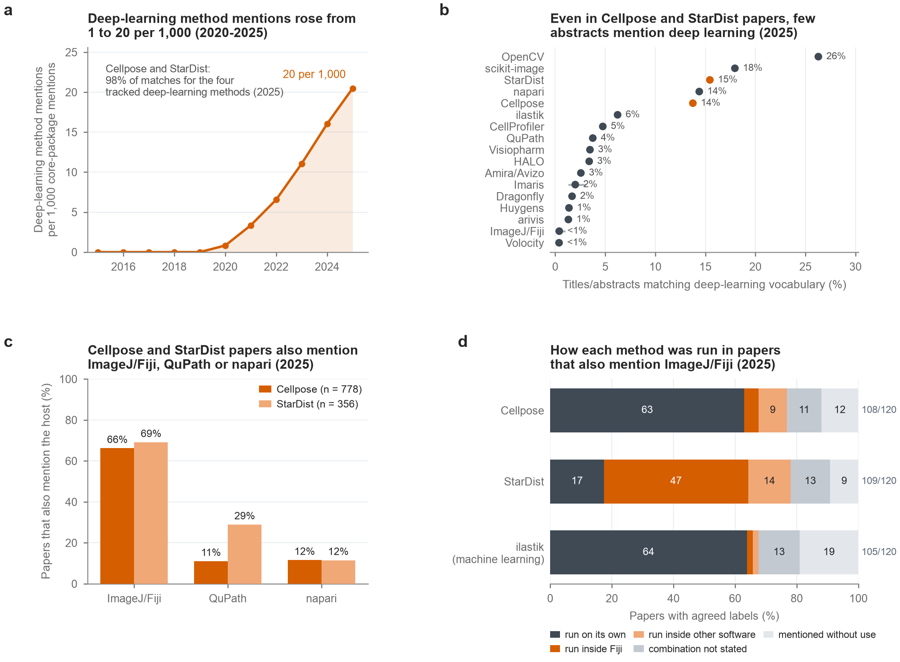

In [6]:
OUTPUT_STEM = 'Figure6__deep_learning'
fig = figure.build_figure()
with TemporaryDirectory(prefix='figure5-notebook-') as notebook_dir, TemporaryDirectory(prefix='figure5-module-') as module_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=notebook_dir)
    figure.main(out_dir=module_dir)
    notebook_png = Path(notebook_dir) / f'{OUTPUT_STEM}.png'
    module_png = Path(module_dir) / f'{OUTPUT_STEM}.png'
    notebook_image = mpimg.imread(notebook_png)
    module_image = mpimg.imread(module_png)
    assert notebook_image.shape == module_image.shape, (notebook_image.shape, module_image.shape)
    np.testing.assert_array_equal(notebook_image, module_image)
    print(f'PNG shape: {notebook_image.shape}; mean absolute pixel difference: {np.abs(notebook_image - module_image).mean():.6f}')
    from io import BytesIO
    from PIL import Image as PILImage
    preview = PILImage.open(notebook_png)
    preview.thumbnail((900, 900))
    preview_bytes = BytesIO()
    preview.save(preview_bytes, format='PNG')
    display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')